# 02 — Optical flow: following pixels without learning their names

[Notebook 01](./01_motion_and_background_subtraction.ipynb) found suspicious regions. Now we ask a more temporal question: **where did recognizable image points move between frames?**

Optical flow estimates apparent image motion. It does not automatically identify objects, understand three-dimensional movement, or know that our robot may be approaching consciousness.

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np

from _helpers.motion_background import (
    ensure_opencv_sample_video,
    make_robot_sequence,
    read_video_frames,
)
from _helpers.optical_flow import (
    plot_corner_xy_gradients,
    plot_corner_parameter_sweep,
    plot_known_robot_flow,
    plot_motion_vector_story,
    plot_pyramid_experiment,
    plot_real_video_tracks,
    plot_robot_tracks,
    plot_why_corners,
)
from wave_part_dual.tracking import detect_corners, track_points_forward_backward

plt.rcParams['figure.dpi'] = 75

## 1. From changed pixels to motion vectors

A **motion vector** has a starting position and a displacement. If a point moves from `(x, y)` to `(x + dx, y + dy)`, its image motion is `(dx, dy)` pixels. Direction matters; distance alone would not tell us whether the robot escaped left, right, or vertically into a more ambitious notebook.

We know the synthetic robot's true center, so the first example contains no estimation yet—only the thing we want an algorithm to recover.

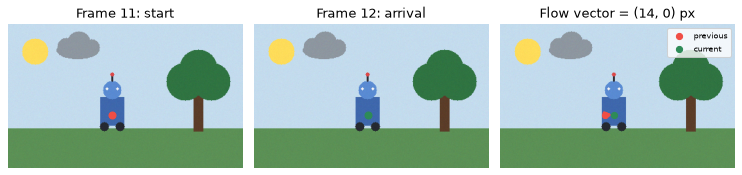

In [2]:
frames, true_robot_masks, true_centers = make_robot_sequence()
plot_motion_vector_story(frames, true_centers, previous_index=11, current_index=12)

The vector is measured in **image coordinates**: positive `x` goes right and positive `y` goes down. It describes how the projection moved across pixels, not necessarily the object's physical velocity in the world. Camera motion, object motion, depth, and perspective can all contribute.

## 2. Why trackers develop a corner preference

To follow a small image patch, it should look distinctive nearby:

- A flat patch looks the same after almost any small shift.
- A straight edge reveals motion across the edge but not clearly along it. This ambiguity is called the **aperture problem**.
- A corner changes in two directions and provides a much better local address.

The heatmaps below are **corner-strength maps**, not motion. OpenCV examines a small neighborhood around every pixel and measures how much its brightness changes in two directions. It keeps the weaker directional response as the score:

- weak in both directions → flat area;
- strong in one but weak in the other → edge with an uncertain position along it;
- strong in both directions → corner with a recognizable two-dimensional address.

Two controls are exposed for experimentation:

- `blockSize` is the neighborhood used to collect local evidence. A larger block sees more context and usually creates a broader, less precisely localized response.
- `ksize` is the odd-sized Sobel derivative kernel used to measure brightness changes. Larger values smooth over a wider neighborhood and alter the response strength.

Their effects depend on feature size, so `15` and `7` are not universally better than `7` and `3`; they simply ask the corner detector to examine the world with wider spectacles.

> For brave enthusiasts interested in how three rectangles become a philosophical argument about addresses: [`plot_why_corners()` implementation](./_helpers/optical_flow.py). OpenCV also provides [`cornerMinEigenVal` documentation](https://docs.opencv.org/4.x/dd/d1a/group__imgproc__feature.html).

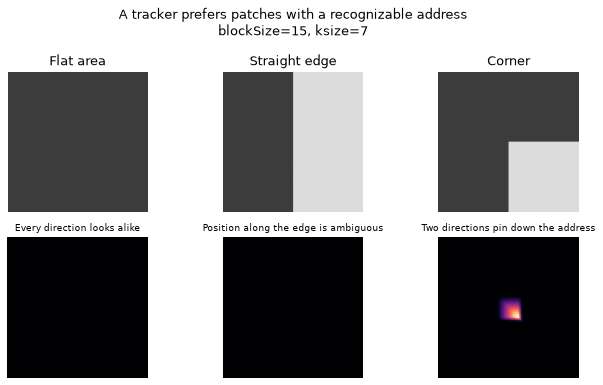

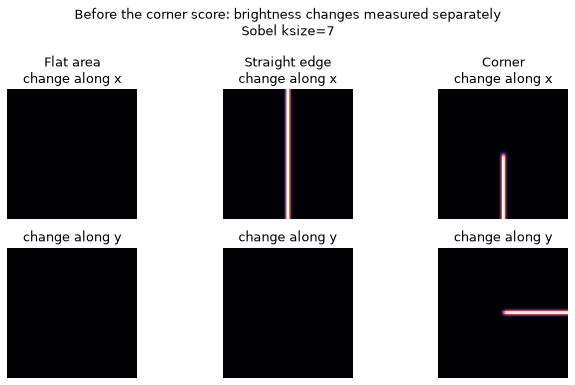

In [3]:
plot_why_corners(blockSize=15, ksize=7)
plot_corner_xy_gradients(ksize=7)

> **Reading the directional plots:** `change along x` measures what changes while moving left or right, so it highlights mostly **vertical edges**. `change along y` measures movement up or down and highlights mostly **horizontal edges**. The straight vertical edge therefore has strong x evidence but almost no y evidence; the corner has both. `cornerMinEigenVal` combines these local gradients, finds two principal directional strengths—which may be rotated rather than perfectly horizontal and vertical—and keeps the weaker one. A corner survives because neither direction is weak.

## 3. Shi–Tomasi: choosing points worth following

OpenCV's `goodFeaturesToTrack` uses the **Shi–Tomasi** criterion to select strong corners. The name sounds like a respected detective because that is approximately its job.

Three controls are enough for today:

- `max_corners`: an upper limit, not a promise;
- `quality_level`: how strong a corner must be relative to the best one;
- `min_distance`: how much personal space selected points require.

We restrict detection to the known robot mask so the tree does not steal every good corner before the experiment starts.

### Further reading, mostly to provide comfort through its mere existence

- [OpenCV's Shi–Tomasi tutorial](https://docs.opencv.org/4.x/d8/dd8/tutorial_good_features_to_track.html) gives the criterion, parameters, and a practical `goodFeaturesToTrack` example.
- [`goodFeaturesToTrack` API documentation](https://docs.opencv.org/4.x/dd/d1a/group__imgproc__feature.html#ga1d6bb77486c8f92d79c8793ad995d541) records exactly what OpenCV accepts and returns.
- Shi and Tomasi's original 1994 paper, [*Good Features to Track*](https://users.cs.duke.edu/~tomasi/papers/shi/TR_93-1399_Cornell.pdf), explains why the weaker eigenvalue becomes the selection criterion and discusses what makes features survive tracking.

Reading the paper is entirely optional. Its presence alone confirms that two real and presumably very patient people thought carefully about this so we do not have to reconstruct 1994 tonight.

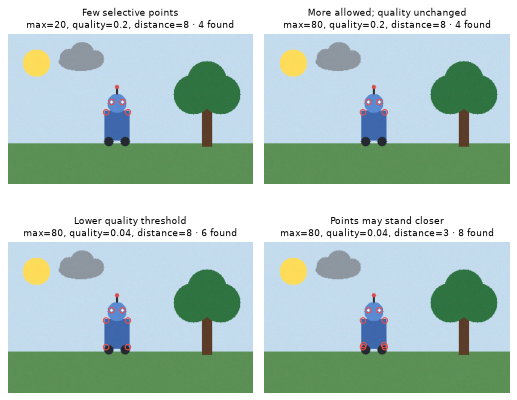

In [4]:
corner_results = plot_corner_parameter_sweep(
    frames[11], true_robot_masks[11]
)

> **Observation:** allowing more points does nothing once all acceptable corners are already selected. Lowering `quality_level` admits weaker candidates; reducing `min_distance` allows several points to crowd around the same visual detail. More points are not automatically more independent information.

In [5]:
frames[11].shape, true_robot_masks[11].shape

((220, 360, 3), (220, 360))

### Just out of curiosity: what if we search the entire image?

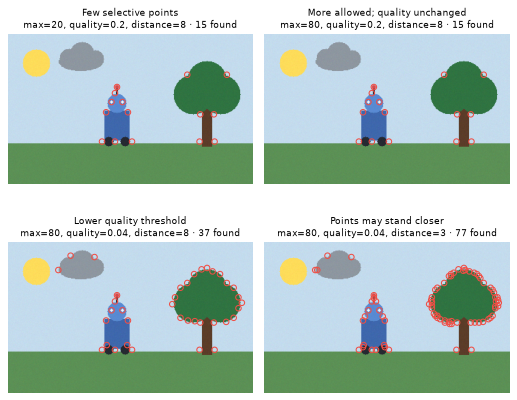

In [6]:
corner_results_test = plot_corner_parameter_sweep(
    frames[11],
    roi_mask=None, #.np.ones_like(true_robot_masks[11])
)

> **Observation:** Without the robot mask, Shi–Tomasi faithfully selects the strongest corners anywhere in the scene. It understands corner quality, not our current emotional investment in the robot.

## 4. Lucas–Kanade: where did each patch go?

> **Shi–Tomasi versus Lucas–Kanade:** Shi–Tomasi examines one frame and **chooses recognizable points** worth tracking. Lucas–Kanade receives those points plus the next frame and **estimates where they moved**. Shi hires; Lucas follows; the tree occasionally steals employees.

The **Lucas–Kanade (LK)** method compares a small neighborhood around each selected point and estimates the displacement that makes the two frames agree best. We can use it without inviting the derivation to dinner. Its useful assumptions are:

1. **Brightness is roughly constant:** the same point looks similar in both frames.
2. **Motion is locally coherent:** nearby pixels in a small patch move similarly.
3. **Motion is not absurdly large:** the search needs a reasonable starting neighborhood. Pyramids will help shortly.

We also perform a practical honesty check: track each point forward, then backward. If it cannot return near its starting position, we distrust it.

> Curious about the machinery? [`detect_corners()` and forward–backward LK implementation](../../src/wave_part_dual/tracking/optical_flow.py). OpenCV documents [`calcOpticalFlowPyrLK`](https://docs.opencv.org/4.x/dc/d6b/group__video__track.html#ga473e4b886d0bcc6b65831eb88ed93323) for anyone experiencing unusual mathematical courage.

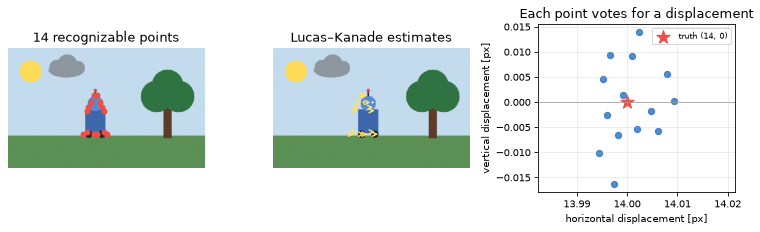

In [7]:
known_flow = plot_known_robot_flow(
    frames,
    true_robot_masks,
    true_centers,       # used only for the third visualization below
    previous_index=11,
    current_index=12,
    win_size=(21, 21),  # local patch size around each point
    max_level=3,        # original image + 3 smaller pyramid levels
)

Each point estimates motion independently, so the blue votes are not identical. Most should gather near the red star—the known robot displacement. Small disagreement is normal; collective agreement is more trustworthy than worshipping one heroic pixel.

## 5. Pyramids: temporarily make a large jump look smaller

Lucas–Kanade is happiest with small motion. An **image pyramid** creates progressively smaller versions of each frame. A 42-pixel jump at full resolution becomes roughly 21 pixels one level down and 10 pixels another level down. LK estimates the coarse motion first, then refines it at larger resolutions.

Below we intentionally skip several frames. Green tracks end near the known displacement; red ones passed the round-trip check but still reached the wrong destination. A point can match a similar-looking but incorrect patch and then successfully match back again—like confidently taking the wrong train and returning on the same one. So **kept means consistent, not proven correct**. We can expose the red mistakes only because the synthetic robot provides the true displacement; real video usually withholds that answer key.

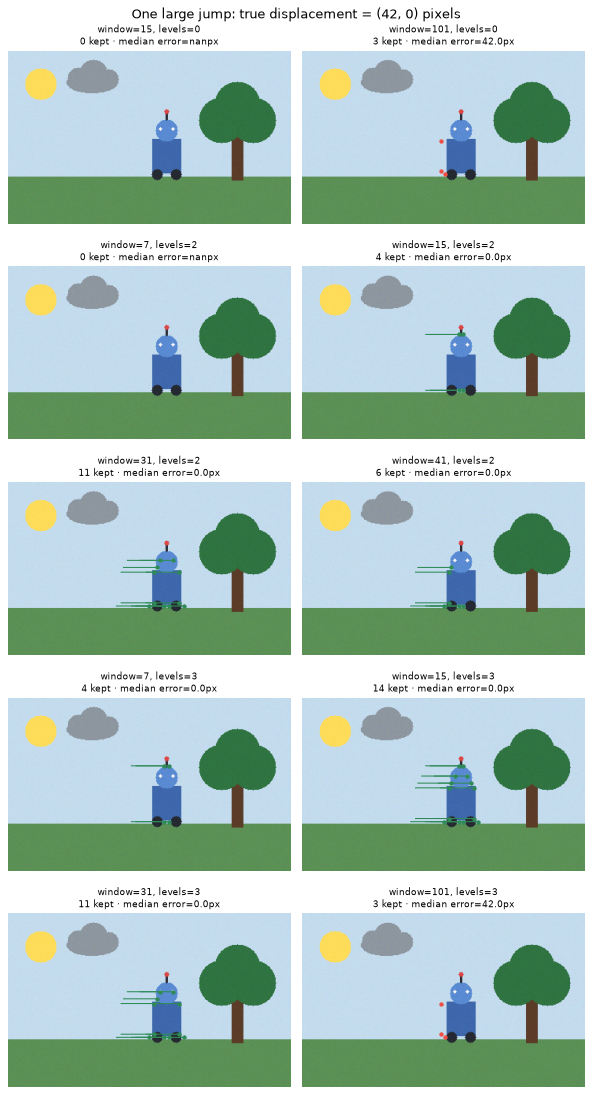

In [80]:
configurations = (
    ((15, 15), 0),
    ((101, 101), 0),
    ((7, 7), 2),
    ((15, 15), 2),
    ((31, 31), 2),
    ((41, 41), 2),
    ((7, 7), 3),
    ((15, 15), 3),
    ((31, 31), 3),
    ((101, 101), 3),
)

pyramid_results = plot_pyramid_experiment(
    frames,
    true_robot_masks,
    true_centers,
    previous_index=11,
    current_index=14,
    configurations=configurations,
)

> **Observation:** a larger window sees more context, while pyramid levels reduce the apparent displacement before refinement. Both can help large motion, but very large windows may mix different objects and extra pyramid levels cannot restore a point that became invisible.

### Review in case the above is not clear enough—which is entirely possible

1. **Shi–Tomasi chooses** recognizable points in frame 1.
2. **Lucas–Kanade searches** for each point in frame 2. `win_size` controls how much surrounding context it examines.
3. `max_level` controls how deeply it may enter the image pyramid. At the smallest allowed image, a large movement looks easier; Lucas then refines the estimate through every larger level back to the original image.
4. The final movement is `point_in_frame_2 - point_in_frame_1 = (dx, dy)`.
5. For the round-trip check, Lucas independently tracks frame 2 → frame 1 with the same settings. A point returning near its origin is kept; the rest are retired. Kept still means *consistent*, not guaranteed correct.

**Why a pyramid?** Centered image levels resemble one: the full-resolution image forms the wide base and progressively smaller images form the upper layers. Confusing people was merely a useful side effect.

For our 42-pixel movement with `max_level=3`:

```text
level 3: estimate about 5.25 px
level 2: refine about 10.5 px
level 1: refine about 21 px
level 0: finish at the original 42 px
```

So `max_level=3` means **start no deeper than level 3 and use levels 3 → 2 → 1 → 0**, not *check only a mysterious 5.25-pixel image*.

## 6. A point's career can end

Tracking repeatedly means using estimated points from one frame as the starting points for the next. In this experiment, Shi–Tomasi chooses the initial points **once** at `start_index`. Lucas–Kanade then tracks the survivors through every adjacent pair—frame 1 → 2, 2 → 3, and so on until `end_index`. We do not detect replacements, so the active count can only stay unchanged or decrease.

Errors can accumulate into **drift**, points can leave the image, and occlusion can replace the original patch with something unrelated.

Our robot approaches the tree. Points that fail the forward–backward check are retired instead of being forced to invent a career behind the leaves. Real systems often detect new features periodically because a shrinking workforce cannot track forever.

> in case you feel like you need to review code for that: [`plot_robot_tracks()` implementation](./_helpers/optical_flow.py).

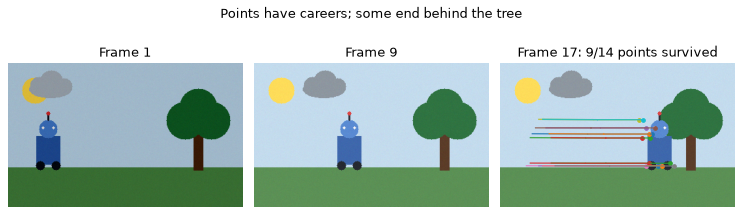

In [88]:
robot_trajectories, surviving_robot_points = plot_robot_tracks(
    frames, true_robot_masks, start_index=1, end_index=17
)

## 7. Real frames: points enter the workplace

We return to OpenCV's fixed-camera `vtest.avi`. MOG2 supplies a rough moving-foreground mask only for choosing initial corners; Lucas–Kanade then follows those points across frames. This combines [notebook 01's](./01_motion_and_background_subtraction.ipynb) candidate evidence with today's temporal motion.

We do **not** redetect lost points here. The declining active count is therefore expected and useful: it exposes the limits instead of quietly hiring replacements.

In [89]:
video_path = ensure_opencv_sample_video(
    Path('../../data/object_tracking/vtest.avi')
)
real_frames, fps = read_video_frames(video_path, maximum_frames=90)
print(f'Read {len(real_frames)} frames at {fps:.1f} FPS')

Read 90 frames at 10.0 FPS


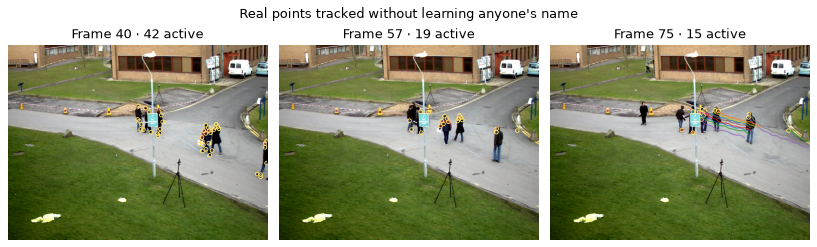

In [90]:
real_trajectories, surviving_real_points = plot_real_video_tracks(
    real_frames, start_index=40, end_index=75, maximum_points=80
)

The colored histories show image paths, not object identities. Several points may belong to one person; one point may drift onto the background; and a person can survive after every original point is lost. Point tracking is valuable evidence, but the paperwork for a persistent object identity is still waiting in notebook 03.

> If tracking anonymous pedestrians suddenly becomes your calling: [`plot_real_video_tracks()` implementation](./_helpers/optical_flow.py).

## Reflection

Short answers are enough; optical flow has already moved plenty today.

1. Why is a corner generally easier to track than a flat patch or straight edge?
2. What does Lucas–Kanade assume about a point between nearby frames?
3. Why do image pyramids help with larger displacement?
4. What does the forward–backward check reject? Can a consistent point still be wrong?
5. Why is a collection of tracked points still not the same as an object tracker?

## Takeaway

Sparse optical flow follows distinctive image points through time. Corners provide useful local addresses; Lucas–Kanade estimates their displacement; pyramids help with larger motion; and consistency checks retire some unreliable tracks.

We can now observe **where visual evidence traveled**, but we still do not maintain one persistent object identity through scale change, occlusion, and failure. That is the next creature waiting behind the tree.